# Real CMS Calibration Data — EDA

Exploration of the committed **real** CMS Medicare Physician & Other Practitioners snapshot
(provider-service aggregates) that calibrates the synthetic claim generator, and a look at the
generated claim population it produces. Production logic lives in `src/`; this notebook is a
thin analytical view.

*Provenance: `data/reference/cms_snapshot_metadata.json` · method: `docs/labeling.md`*

In [1]:
import sys, json
sys.path.insert(0, "..")
import pandas as pd
from src.data.ingest_cms import load_snapshot
from src.utils.viz import apply_mpl_style, MODEL_COLORS, SEQUENTIAL_BLUES
apply_mpl_style()

cms = load_snapshot("../data/reference/cms_provider_service_sample.csv")
meta = json.load(open("../data/reference/cms_snapshot_metadata.json"))
print(f"{len(cms)} provider-service rows · {cms['provider_type'].nunique()} specialties · retrieved {meta['retrieved_date']}")
cms.head(3)

480 provider-service rows · 12 specialties · retrieved 2026-08-06


,npi,provider_type,state,ruca,hcpcs,hcpcs_desc,drug_ind,place_of_service,total_benes,total_services,total_bene_day_services,avg_submitted,avg_allowed,avg_paid
0,1003000126,Internal Medicine,MD,1.0,99221,Initial hospital care with straightforward or ...,N,F,36,36,36,284.378889,79.063889,60.828889
1,1003000126,Internal Medicine,MD,1.0,99222,Initial hospital care with straightforward or ...,N,F,150,150,150,352.176333,126.340800,95.675600
2,1003000126,Internal Medicine,MD,1.0,99223,Initial hospital care with moderate level of m...,N,F,63,63,63,783.997302,170.360000,134.300476


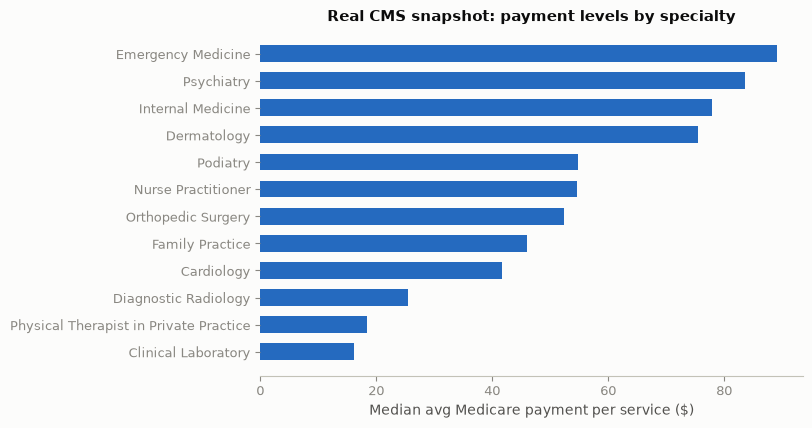

In [2]:
# Payment levels differ sharply by specialty — the reason peer normalization exists
import matplotlib.pyplot as plt
spec = (cms.groupby("provider_type")["avg_paid"].median().sort_values())
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(spec.index, spec.values, color=SEQUENTIAL_BLUES[4], height=0.62)
ax.set_xlabel("Median avg Medicare payment per service ($)")
ax.set_title("Real CMS snapshot: payment levels by specialty")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plt.show()

In [3]:
# Facility vs office split per specialty (drives synthetic POS assignment)
fac = (cms.assign(svc=cms["total_services"])
          .groupby("provider_type")
          .apply(lambda g: (g.loc[g["place_of_service"]=="F","svc"].sum()/g["svc"].sum()), include_groups=False)
          .sort_values())
fac.round(3).to_frame("facility_share")

,facility_share
provider_type,
Dermatology,0.000
Physical Therapist in Private Practice,0.000
Clinical Laboratory,0.002
Podiatry,0.003
Orthopedic Surgery,0.028
Nurse Practitioner,0.039
Family Practice,0.132
Internal Medicine,0.207
Cardiology,0.384


## The generated claim population

378,310 claims · 2,000 providers · 30,596 beneficiaries · improper rate 4.45%


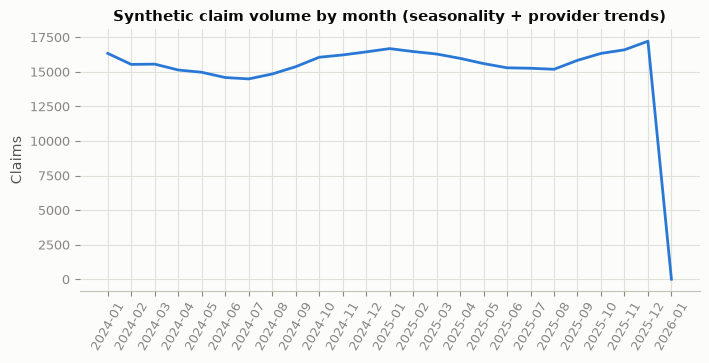

In [4]:
claims = pd.read_parquet("../data/processed/claims.parquet")
labels = pd.read_parquet("../data/processed/labels.parquet")
print(f"{len(claims):,} claims · {claims['provider_id'].nunique():,} providers · "
      f"{claims['bene_id'].nunique():,} beneficiaries · improper rate {labels['is_improper'].mean():.2%}")
monthly = claims.assign(m=pd.to_datetime(claims["service_date"]).dt.to_period("M").astype(str)).groupby("m").size()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(monthly.index, monthly.values, color=MODEL_COLORS["ensemble"])
ax.set_title("Synthetic claim volume by month (seasonality + provider trends)")
ax.set_ylabel("Claims"); ax.tick_params(axis="x", rotation=60)
plt.show()

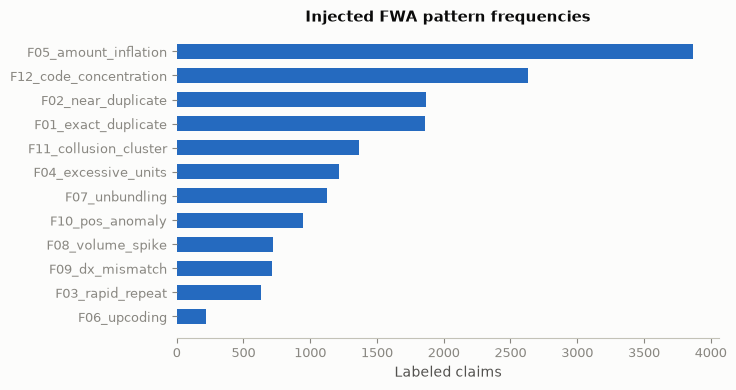

In [5]:
# Injected pattern mix (ground truth — exists only because labels are synthetic)
pat = (labels.loc[labels["is_improper"], "patterns"].str.split(";").explode().value_counts())
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(pat.index[::-1], pat.values[::-1], color=SEQUENTIAL_BLUES[4], height=0.62)
ax.set_title("Injected FWA pattern frequencies"); ax.set_xlabel("Labeled claims")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plt.show()